# Vegetation-Geography-Precipitation Relationship Analysis

**Purpose:** Understand the interplay between precipitation, vegetation (NDVI), and geographic location

**Outputs:**
- 7 publication-quality visualizations
- Agro-ecological zone classifications
- Precipitation-NDVI correlation metrics by district
- Optimal lag estimates for predictive models

**Reference:** See `../../docs/06_VEGETATION_GEOGRAPHY_PRECIPITATION_ANALYSIS.md` for detailed documentation

## Setup

In [2]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import warnings

warnings.filterwarnings("ignore")

# Plotting style
plt.style.use("seaborn-v0_8-darkgrid")
sns.set_palette("husl")

# Display options
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)

print("✓ Imports complete")

✓ Imports complete


In [3]:
# Paths
current = Path.cwd()
project_root = current if (current / "CLAUDE.md").exists() else current.parent.parent

data_path = project_root / "data" / "processed"
figures_path = current / "figures"

# Create figures directory
figures_path.mkdir(parents=True, exist_ok=True)

print(f"Project root: {project_root}")
print(f"Data path: {data_path}")
print(f"Figures path: {figures_path}")

Project root: /Users/a0488240/Documents/Learning/MTech/project/dsba2026
Data path: /Users/a0488240/Documents/Learning/MTech/project/dsba2026/data/processed
Figures path: /Users/a0488240/Documents/Learning/MTech/project/dsba2026/figures


## Data Loading

In [4]:
print("Loading data...\n")

# Load monthly climate data
climate = pd.read_parquet(data_path / "fact_monthly_climate_spark.parquet")
print(f"1. Climate data loaded: {len(climate):,} monthly records")

# Load district coordinates
districts = pd.read_parquet(data_path / "dim_districts_spark.parquet")
print(f"2. District data loaded: {len(districts):,} districts")

print("\n✓ All data loaded")

Loading data...

1. Climate data loaded: 94,141 monthly records
2. District data loaded: 515 districts

✓ All data loaded


In [5]:
# Merge coordinates into climate data
climate = climate.merge(
    districts[["state", "district", "centroid_lat", "centroid_lon"]],
    on=["state", "district"],
    how="left",
)

# Check coverage
coord_coverage = climate["centroid_lat"].notna().mean()
print(f"✓ Coordinates merged: {coord_coverage:.1%} coverage")

# Sample
print("\nSample data:")
print(
    climate[
        [
            "state",
            "district",
            "year",
            "month",
            "precipitation_mm",
            "raw_ndvi_mean",
            "centroid_lat",
            "centroid_lon",
        ]
    ].head()
)

✓ Coordinates merged: 100.0% coverage

Sample data:
            state   district  year  month  precipitation_mm  raw_ndvi_mean  \
0  Andhra Pradesh  Anantapur  2026      2              1.05       0.381474   
1  Andhra Pradesh  Anantapur  2026      2              1.05       0.351842   
2  Andhra Pradesh   Chittoor  2018      4             15.63       0.369976   
3  Andhra Pradesh   Chittoor  2018      4             15.63       0.362818   
4  Andhra Pradesh   Chittoor  2018      8            142.41       0.507777   

   centroid_lat  centroid_lon  
0     14.312066     77.460158  
1     14.312066     77.460158  
2     13.331093     78.927639  
3     13.331093     78.927639  
4     13.331093     78.927639  


In [6]:
print("Data Quality Checks:")
print("=" * 60)

print(f"\nShape: {climate.shape}")
print(f"Year range: {climate['year'].min()} - {climate['year'].max()}")
print(f"States: {climate['state'].nunique()}")
print(f"Districts: {climate['district'].nunique()}")

print(f"\nFeature coverage:")
print(f"  precipitation_mm: {climate['precipitation_mm'].notna().mean():.1%}")
print(f"  raw_ndvi_mean:    {climate['raw_ndvi_mean'].notna().mean():.1%}")
print(f"  coordinates:      {climate['centroid_lat'].notna().mean():.1%}")

print("\n✓ Quality checks passed")

Data Quality Checks:

Shape: (94141, 13)
Year range: 2016 - 2026
States: 26
Districts: 412

Feature coverage:
  precipitation_mm: 100.0%
  raw_ndvi_mean:    100.0%
  coordinates:      100.0%

✓ Quality checks passed


## Analysis 1: Precipitation-NDVI Correlation by District

**Importance:** CRITICAL - Establishes baseline relationship strength

In [7]:
# Calculate district-level correlations
correlations = (
    climate.groupby(["state", "district", "centroid_lat", "centroid_lon"])
    .apply(lambda g: g[["precipitation_mm", "raw_ndvi_mean"]].corr().iloc[0, 1])
    .reset_index(name="precip_ndvi_corr")
)

# Summary statistics
print(
    f"Correlation range: {correlations['precip_ndvi_corr'].min():.3f} to {correlations['precip_ndvi_corr'].max():.3f}"
)
print(f"Median correlation: {correlations['precip_ndvi_corr'].median():.3f}")
print(f"\nDistrict categories:")
print(
    f"  High correlation (r>0.7): {(correlations['precip_ndvi_corr'] > 0.7).sum()} districts (rainfed)"
)
print(
    f"  Medium (0.3<r<0.7):       {((correlations['precip_ndvi_corr'] > 0.3) & (correlations['precip_ndvi_corr'] <= 0.7)).sum()} districts (mixed)"
)
print(
    f"  Low correlation (r<0.3):  {(correlations['precip_ndvi_corr'] <= 0.3).sum()} districts (irrigated)"
)

Correlation range: -0.352 to 0.833
Median correlation: 0.470

District categories:
  High correlation (r>0.7): 20 districts (rainfed)
  Medium (0.3<r<0.7):       306 districts (mixed)
  Low correlation (r<0.3):  88 districts (irrigated)


Loading India state boundaries...
✓ Loaded 36 state boundaries from local file


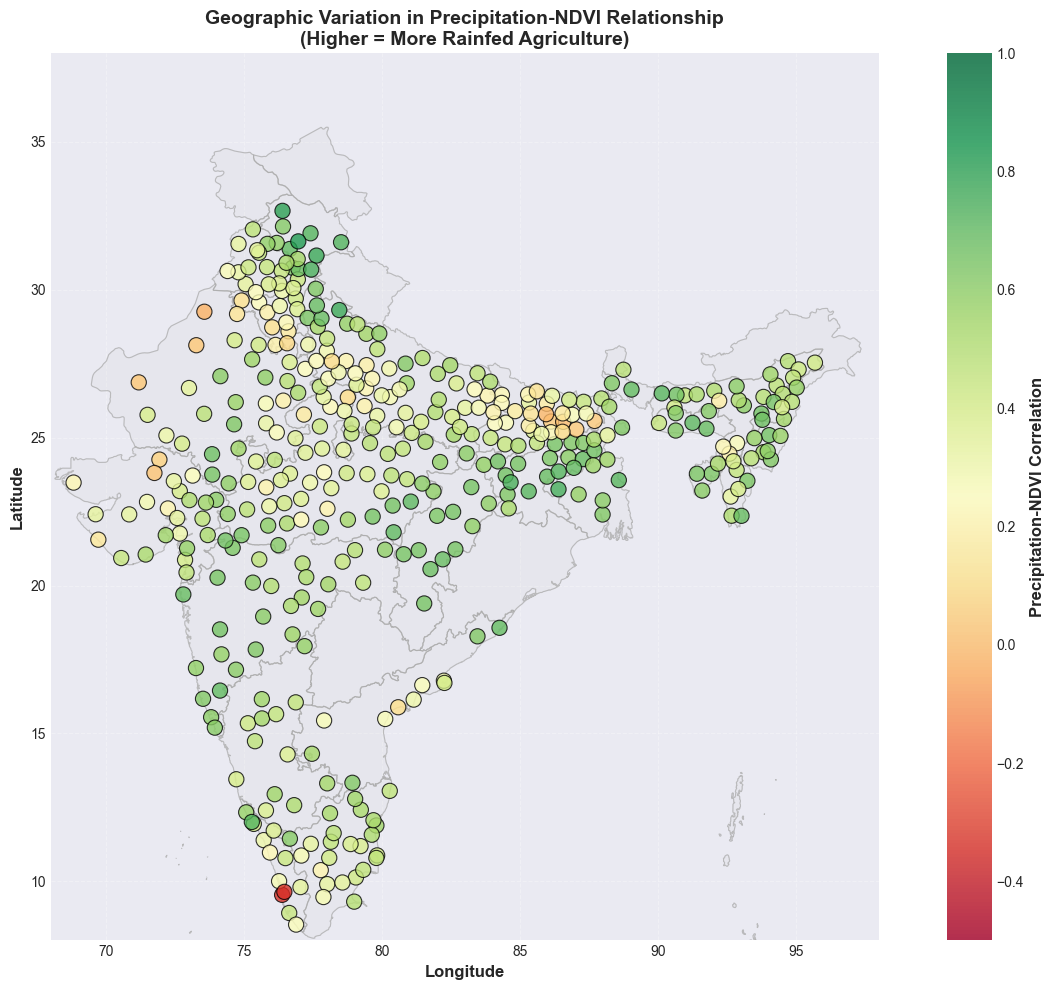

✓ Saved: 01_precip_ndvi_correlation_map.png


In [45]:
# Scatter plot map WITH INDIA STATE BOUNDARIES
import geopandas as gpd
import fiona
from shapely.geometry import shape

fig, ax = plt.subplots(figsize=(14, 10))

# Load India state boundaries using fiona workaround
try:
    print("Loading India state boundaries...")

    # Try local file first
    local_path = project_root / "data" / "raw" / "geography" / "india_states.shp"

    if local_path.exists():
        # Load from local file using fiona directly (avoids geopandas compatibility issue)
        records = []
        with fiona.open(str(local_path), "r") as src:
            crs = src.crs
            for feature in src:
                records.append(
                    {"geometry": shape(feature["geometry"]), **feature["properties"]}
                )
        india_states = gpd.GeoDataFrame(records, crs=crs)
        print(f"✓ Loaded {len(india_states)} state boundaries from local file")

        # Plot state boundaries FIRST (background layer)
        india_states.boundary.plot(
            ax=ax, linewidth=0.8, edgecolor="darkgray", alpha=0.7, zorder=1
        )

        # Optional: Add light fill
        india_states.plot(
            ax=ax,
            color="lightgray",
            alpha=0.15,
            edgecolor="darkgray",
            linewidth=0.8,
            zorder=1,
        )
    else:
        print(f"⚠ Local file not found: {local_path}")
        print("  Run extract_india_manual.ipynb first to create the file")
        print("  Showing scatter plot without boundaries...")

except Exception as e:
    print(f"⚠ Could not load state boundaries: {e}")
    print("  Showing scatter plot without boundaries...")

# Plot scatter points ON TOP of boundaries
scatter = ax.scatter(
    correlations["centroid_lon"],
    correlations["centroid_lat"],
    c=correlations["precip_ndvi_corr"],
    cmap="RdYlGn",
    s=120,  # Slightly larger to be visible over boundaries
    alpha=0.8,
    edgecolors="black",
    linewidth=0.8,
    vmin=-0.5,
    vmax=1.0,
    zorder=3,  # Ensure scatter points are on top
)

# Colorbar
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("Precipitation-NDVI Correlation", fontsize=12, fontweight="bold")

# Labels and title
ax.set_xlabel("Longitude", fontsize=12, fontweight="bold")
ax.set_ylabel("Latitude", fontsize=12, fontweight="bold")
ax.set_title(
    "Geographic Variation in Precipitation-NDVI Relationship\n(Higher = More Rainfed Agriculture)",
    fontsize=14,
    fontweight="bold",
)

# Set axis limits to India's extent
ax.set_xlim(68, 98)  # India longitude range
ax.set_ylim(8, 38)  # India latitude range

# Grid
ax.grid(True, alpha=0.3, linestyle="--", zorder=2)

plt.tight_layout()
plt.savefig(
    figures_path / "01_precip_ndvi_correlation_map.png", dpi=300, bbox_inches="tight"
)
plt.show()

print("✓ Saved: 01_precip_ndvi_correlation_map.png")

## Analysis 2: Temporal Lag Analysis

**Importance:** HIGH - Identifies optimal lag for predictive models

In [46]:
# Sort and create lagged features
climate = climate.sort_values(["state", "district", "year", "month"])

for lag in [1, 2, 3]:
    climate[f"precip_lag{lag}"] = climate.groupby(["state", "district"])[
        "precipitation_mm"
    ].shift(lag)

print("✓ Lagged precipitation features created")

# Calculate correlations for each lag
lag_correlations = []

for lag in [0, 1, 2, 3]:
    precip_col = "precipitation_mm" if lag == 0 else f"precip_lag{lag}"

    # Calculate correlation by group
    def calc_corr(group):
        # Drop NaN values for correlation calculation
        data = group[[precip_col, "raw_ndvi_mean"]].dropna()
        if len(data) > 10:
            return data[precip_col].corr(data["raw_ndvi_mean"])
        else:
            return np.nan

    corr = (
        climate.groupby(["state", "district"], group_keys=False)
        .apply(calc_corr)
        .reset_index(name=f"corr_lag{lag}")
    )

    lag_correlations.append(corr)

# Merge all lag correlations
lag_results = lag_correlations[0]
for i in range(1, 4):
    lag_results = lag_results.merge(lag_correlations[i], on=["state", "district"])

# Find optimal lag for each district
lag_cols = ["corr_lag0", "corr_lag1", "corr_lag2", "corr_lag3"]

# Get the column name with max correlation for each row
optimal_lag_names = lag_results[lag_cols].idxmax(axis=1)

# Extract the lag number, handling NaN values
lag_results["optimal_lag"] = (
    optimal_lag_names.str.replace("corr_lag", "")
    .fillna("0")  # Fill NaN with "0" before converting to int
    .astype(int)
)

print("\nDistribution of optimal lags:")
print(lag_results["optimal_lag"].value_counts().sort_index())

print(f"\nAverage correlations by lag:")
for lag in [0, 1, 2, 3]:
    avg_corr = lag_results[f"corr_lag{lag}"].mean()
    print(f"  Lag {lag} months: r = {avg_corr:.3f}")

# Show how many districts have valid correlations
valid_count = lag_results[lag_cols].notna().all(axis=1).sum()
total_count = len(lag_results)
print(
    f"\nDistricts with valid correlations: {valid_count}/{total_count} ({valid_count/total_count*100:.1f}%)"
)

✓ Lagged precipitation features created

Distribution of optimal lags:
optimal_lag
0     46
1    183
2    136
3     49
Name: count, dtype: int64

Average correlations by lag:
  Lag 0 months: r = 0.450
  Lag 1 months: r = 0.534
  Lag 2 months: r = 0.518
  Lag 3 months: r = 0.435

Districts with valid correlations: 413/414 (99.8%)


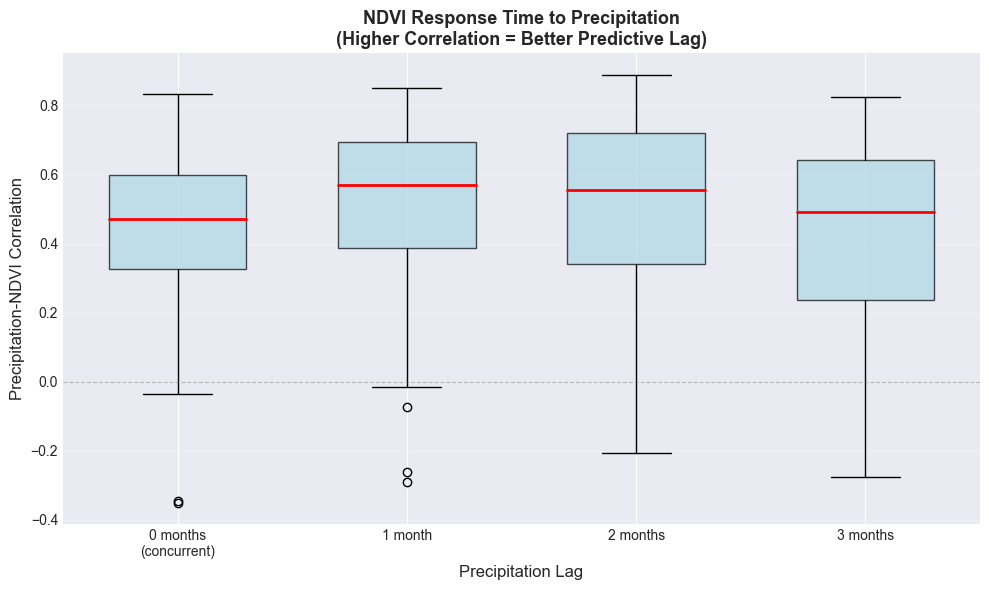

✓ Saved: 02_precipitation_lag_response.png


In [47]:
# Box plots
fig, ax = plt.subplots(figsize=(10, 6))

box_data = [lag_results[f"corr_lag{lag}"].dropna() for lag in [0, 1, 2, 3]]
bp = ax.boxplot(
    box_data,
    positions=[0, 1, 2, 3],
    widths=0.6,
    patch_artist=True,
    boxprops=dict(facecolor="lightblue", alpha=0.7),
    medianprops=dict(color="red", linewidth=2),
)

ax.set_xticks([0, 1, 2, 3])
ax.set_xticklabels(["0 months\n(concurrent)", "1 month", "2 months", "3 months"])
ax.set_ylabel("Precipitation-NDVI Correlation", fontsize=12)
ax.set_xlabel("Precipitation Lag", fontsize=12)
ax.set_title(
    "NDVI Response Time to Precipitation\n(Higher Correlation = Better Predictive Lag)",
    fontsize=13,
    fontweight="bold",
)
ax.grid(True, alpha=0.3, axis="y")
ax.axhline(y=0, color="gray", linestyle="--", linewidth=0.8, alpha=0.5)

plt.tight_layout()
plt.savefig(
    figures_path / "02_precipitation_lag_response.png", dpi=300, bbox_inches="tight"
)
plt.show()

print("✓ Saved: 02_precipitation_lag_response.png")

## Analysis 3: Geographic Gradients

In [48]:
# District averages
district_summary = (
    climate.groupby(["state", "district", "centroid_lat", "centroid_lon"])
    .agg({"precipitation_mm": ["mean", "std"], "raw_ndvi_mean": ["mean", "std"]})
    .reset_index()
)

district_summary.columns = [
    "state",
    "district",
    "lat",
    "lon",
    "precip_mean",
    "precip_std",
    "ndvi_mean",
    "ndvi_std",
]
district_summary["precip_cv"] = (
    district_summary["precip_std"] / district_summary["precip_mean"]
)
district_summary["ndvi_cv"] = (
    district_summary["ndvi_std"] / district_summary["ndvi_mean"]
)

# Fit gradients
slope_precip_lat, *_ = stats.linregress(
    district_summary["lat"], district_summary["precip_mean"]
)[:2]
slope_ndvi_lat, *_ = stats.linregress(
    district_summary["lat"], district_summary["ndvi_mean"]
)[:2]
slope_precip_lon, *_ = stats.linregress(
    district_summary["lon"], district_summary["precip_mean"]
)[:2]
slope_ndvi_lon, *_ = stats.linregress(
    district_summary["lon"], district_summary["ndvi_mean"]
)[:2]

print(f"Precipitation gradient: {slope_precip_lat:.2f} mm/month per° latitude")
print(f"NDVI gradient:          {slope_ndvi_lat:.4f} per° latitude")
print(f"Precipitation gradient: {slope_precip_lon:.2f} mm/month per° longitude")
print(f"NDVI gradient:          {slope_ndvi_lon:.4f} per° longitude")

Precipitation gradient: 0.16 mm/month per° latitude
NDVI gradient:          -0.0025 per° latitude
Precipitation gradient: 7.34 mm/month per° longitude
NDVI gradient:          0.0050 per° longitude


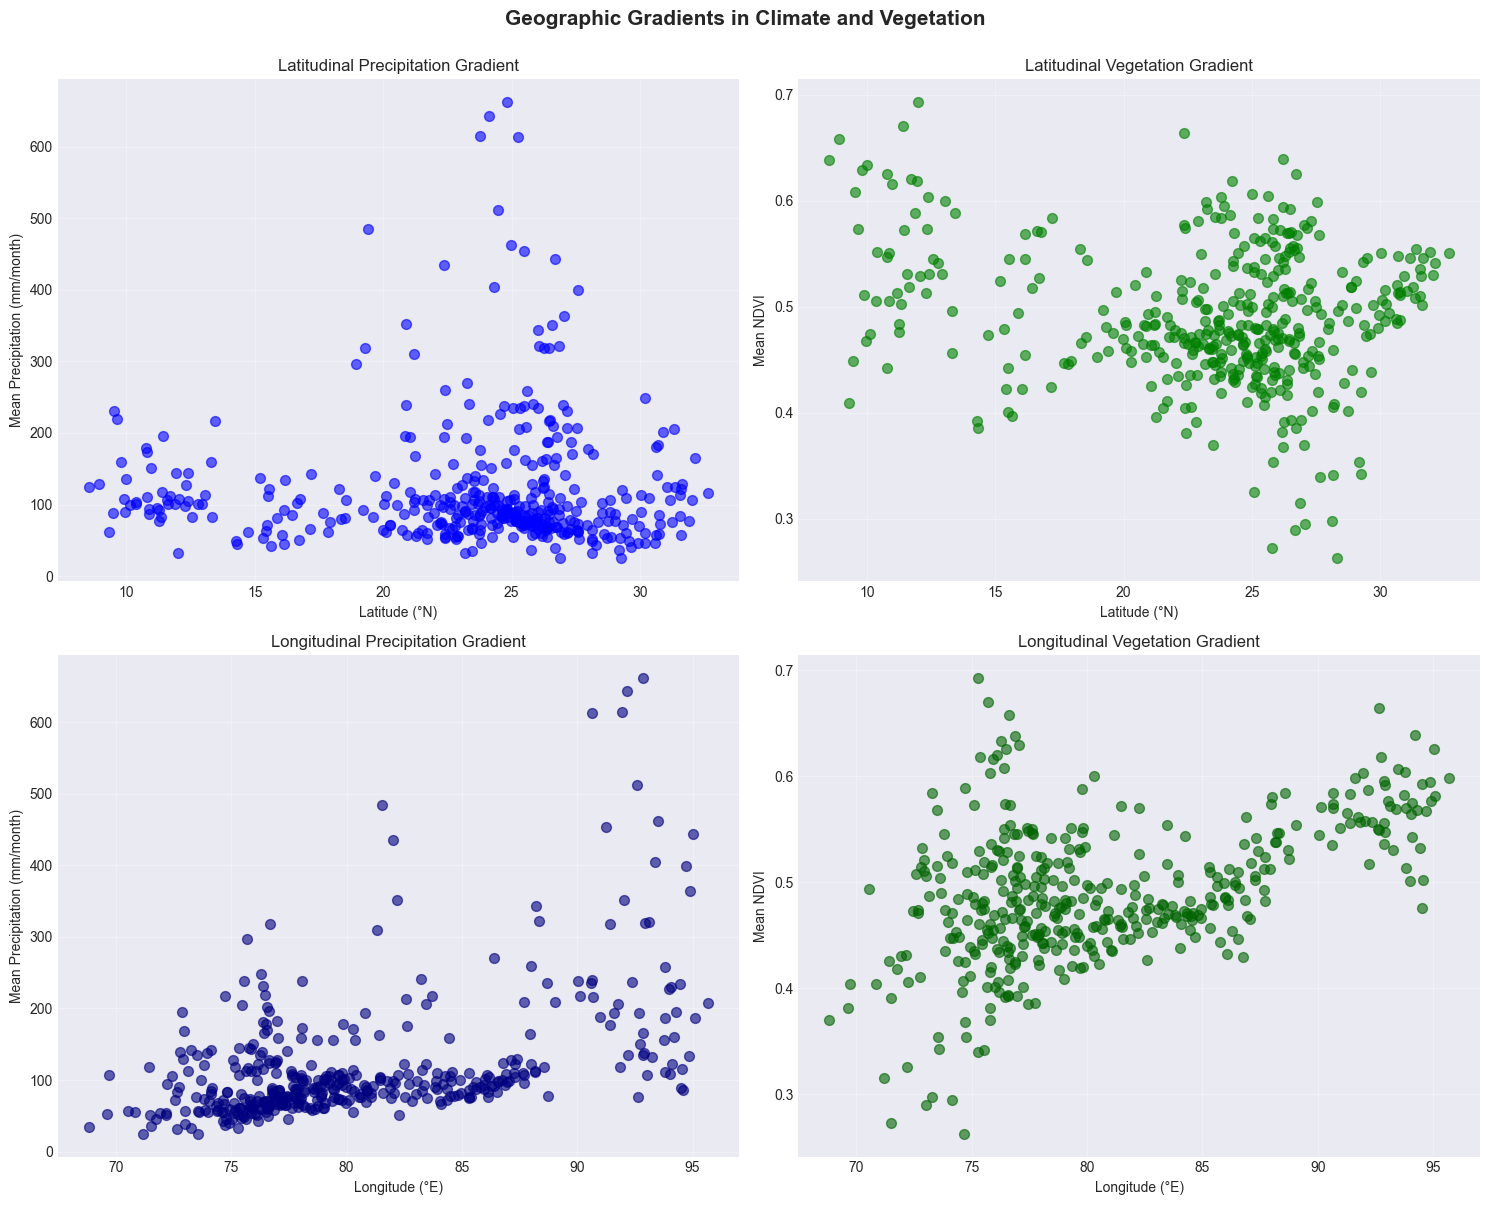

✓ Saved: 03_geographic_gradients.png


In [49]:
# 2x2 subplot grid
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# Precipitation vs Latitude
axes[0, 0].scatter(
    district_summary["lat"],
    district_summary["precip_mean"],
    alpha=0.6,
    s=50,
    color="blue",
)
axes[0, 0].set_xlabel("Latitude (°N)")
axes[0, 0].set_ylabel("Mean Precipitation (mm/month)")
axes[0, 0].set_title("Latitudinal Precipitation Gradient")
axes[0, 0].grid(True, alpha=0.3)

# NDVI vs Latitude
axes[0, 1].scatter(
    district_summary["lat"],
    district_summary["ndvi_mean"],
    alpha=0.6,
    s=50,
    color="green",
)
axes[0, 1].set_xlabel("Latitude (°N)")
axes[0, 1].set_ylabel("Mean NDVI")
axes[0, 1].set_title("Latitudinal Vegetation Gradient")
axes[0, 1].grid(True, alpha=0.3)

# Precipitation vs Longitude
axes[1, 0].scatter(
    district_summary["lon"],
    district_summary["precip_mean"],
    alpha=0.6,
    s=50,
    color="navy",
)
axes[1, 0].set_xlabel("Longitude (°E)")
axes[1, 0].set_ylabel("Mean Precipitation (mm/month)")
axes[1, 0].set_title("Longitudinal Precipitation Gradient")
axes[1, 0].grid(True, alpha=0.3)

# NDVI vs Longitude
axes[1, 1].scatter(
    district_summary["lon"],
    district_summary["ndvi_mean"],
    alpha=0.6,
    s=50,
    color="darkgreen",
)
axes[1, 1].set_xlabel("Longitude (°E)")
axes[1, 1].set_ylabel("Mean NDVI")
axes[1, 1].set_title("Longitudinal Vegetation Gradient")
axes[1, 1].grid(True, alpha=0.3)

plt.suptitle(
    "Geographic Gradients in Climate and Vegetation",
    fontsize=15,
    fontweight="bold",
    y=1.00,
)
plt.tight_layout()
plt.savefig(figures_path / "03_geographic_gradients.png", dpi=300, bbox_inches="tight")
plt.show()

print("✓ Saved: 03_geographic_gradients.png")

## Analysis 4: Regional Clustering (Agro-Ecological Zones)

In [50]:
# Create feature matrix
cluster_features = district_summary[
    ["precip_mean", "precip_cv", "ndvi_mean", "ndvi_cv", "lat", "lon"]
]

# Standardize
scaler = StandardScaler()
features_scaled = scaler.fit_transform(cluster_features)

print(
    f"Feature matrix: {features_scaled.shape[0]} districts × {features_scaled.shape[1]} features"
)

Feature matrix: 414 districts × 6 features


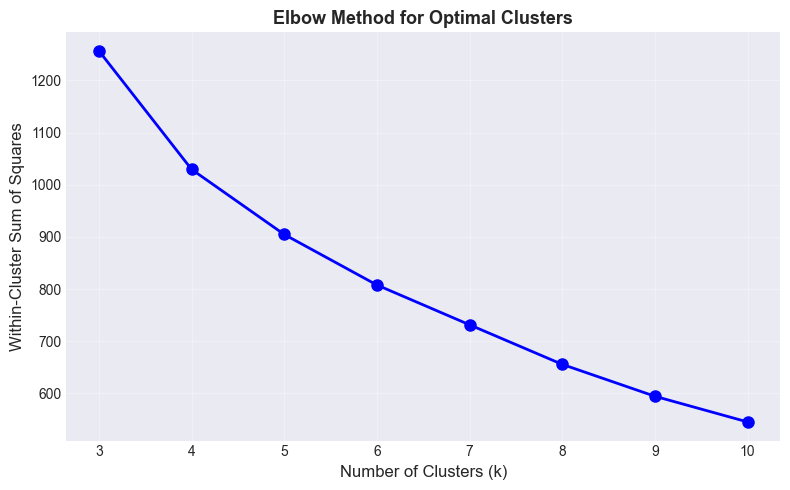

✓ Saved: 04_elbow_curve.png

Cluster Profiles:
         precip_mean  ndvi_mean     lat     lon  n_districts
cluster                                                     
0             73.611      0.436  26.049  77.125           95
1            168.853      0.560  25.114  91.635           50
2            105.867      0.528  12.850  77.821           63
3            108.800      0.488  26.173  82.111          126
4            440.979      0.554  24.972  90.740           20
5             92.735      0.456  22.103  73.966           60


In [51]:
# Elbow method
inertias = []
K_range = range(3, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(features_scaled)
    inertias.append(kmeans.inertia_)

# Plot
plt.figure(figsize=(8, 5))
plt.plot(K_range, inertias, "bo-", linewidth=2, markersize=8)
plt.xlabel("Number of Clusters (k)", fontsize=12)
plt.ylabel("Within-Cluster Sum of Squares", fontsize=12)
plt.title("Elbow Method for Optimal Clusters", fontsize=13, fontweight="bold")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(figures_path / "04_elbow_curve.png", dpi=300, bbox_inches="tight")
plt.show()

print("✓ Saved: 04_elbow_curve.png")

# Apply clustering with k=6
k_optimal = 6
kmeans = KMeans(n_clusters=k_optimal, random_state=42, n_init=10)
district_summary["cluster"] = kmeans.fit_predict(features_scaled)

# Cluster profiles
cluster_profiles = (
    district_summary.groupby("cluster")
    .agg(
        {
            "precip_mean": "mean",
            "ndvi_mean": "mean",
            "lat": "mean",
            "lon": "mean",
            "district": "count",
        }
    )
    .rename(columns={"district": "n_districts"})
    .round(3)
)

print("\nCluster Profiles:")
print(cluster_profiles)

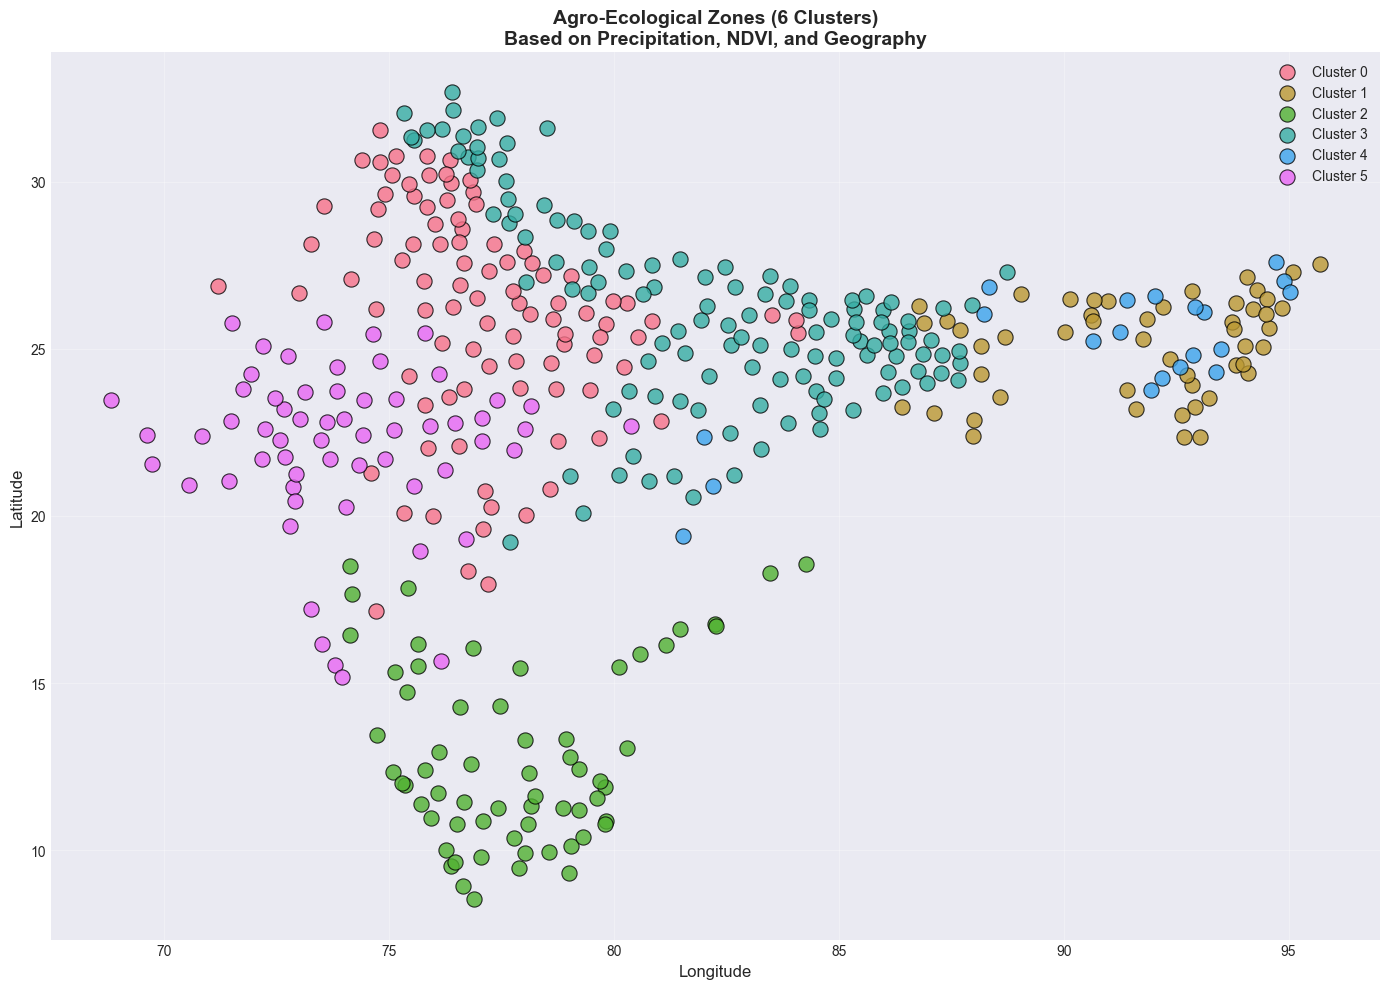

✓ Saved: 05_agro_ecological_zones.png


In [52]:
# Cluster map
fig, ax = plt.subplots(figsize=(14, 10))

for cluster_id in range(k_optimal):
    cluster_data = district_summary[district_summary["cluster"] == cluster_id]
    ax.scatter(
        cluster_data["lon"],
        cluster_data["lat"],
        label=f"Cluster {cluster_id}",
        s=120,
        alpha=0.8,
        edgecolors="black",
        linewidth=0.8,
    )

ax.set_xlabel("Longitude", fontsize=12)
ax.set_ylabel("Latitude", fontsize=12)
ax.set_title(
    f"Agro-Ecological Zones ({k_optimal} Clusters)\nBased on Precipitation, NDVI, and Geography",
    fontsize=14,
    fontweight="bold",
)
ax.legend(loc="best", fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(figures_path / "05_agro_ecological_zones.png", dpi=300, bbox_inches="tight")
plt.show()

print("✓ Saved: 05_agro_ecological_zones.png")

## Analysis 5: Optimal Precipitation Ranges by Region

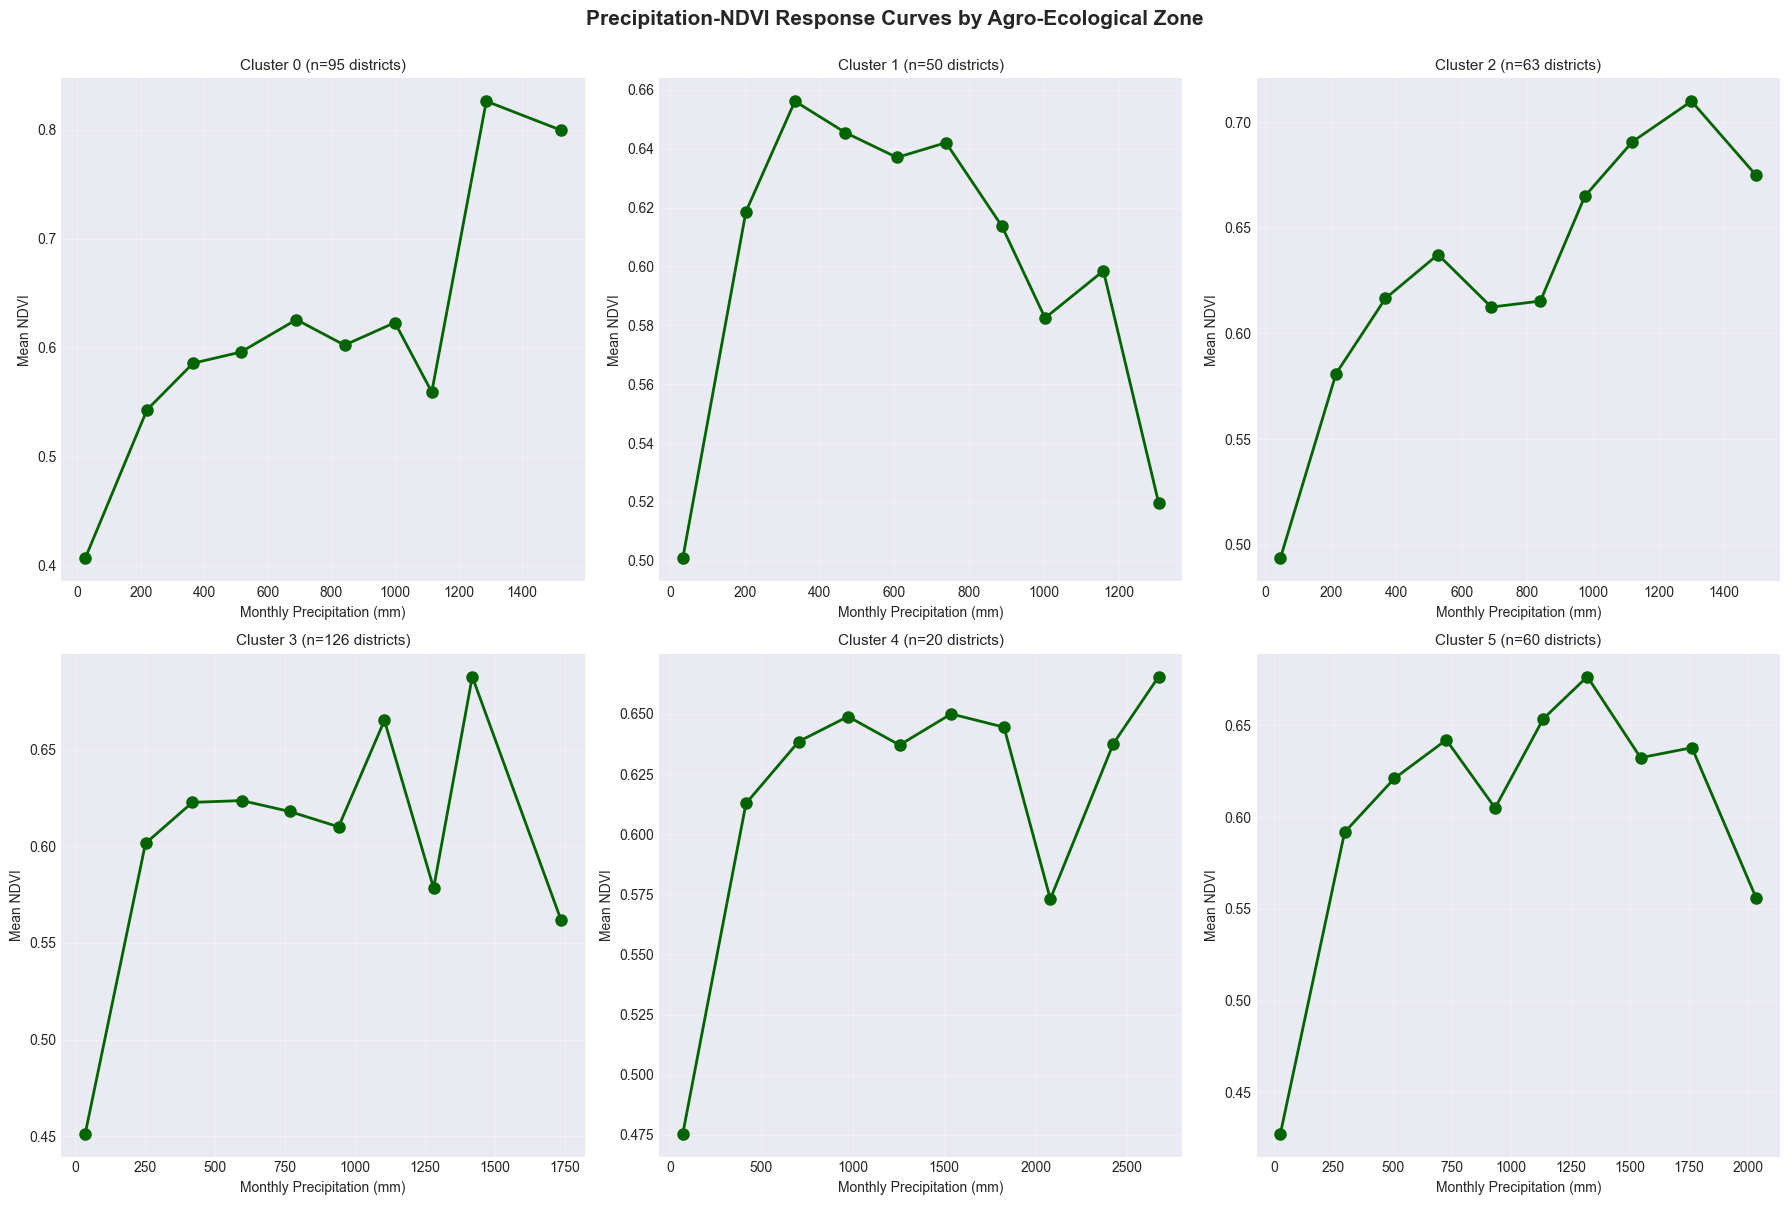

✓ Saved: 06_optimal_precipitation_by_zone.png


In [53]:
# Response curves by cluster
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for cluster_id in range(k_optimal):
    cluster_districts = district_summary[district_summary["cluster"] == cluster_id][
        ["state", "district"]
    ]
    cluster_climate = climate.merge(cluster_districts, on=["state", "district"])

    cluster_climate["precip_bin"] = pd.cut(cluster_climate["precipitation_mm"], bins=10)

    ndvi_by_precip = (
        cluster_climate.groupby("precip_bin")
        .agg({"raw_ndvi_mean": "mean", "precipitation_mm": "mean"})
        .dropna()
    )

    axes[cluster_id].plot(
        ndvi_by_precip["precipitation_mm"],
        ndvi_by_precip["raw_ndvi_mean"],
        marker="o",
        linewidth=2,
        markersize=8,
        color="darkgreen",
    )
    axes[cluster_id].set_xlabel("Monthly Precipitation (mm)", fontsize=10)
    axes[cluster_id].set_ylabel("Mean NDVI", fontsize=10)
    axes[cluster_id].set_title(
        f"Cluster {cluster_id} (n={len(cluster_districts)} districts)", fontsize=11
    )
    axes[cluster_id].grid(True, alpha=0.3)

plt.suptitle(
    "Precipitation-NDVI Response Curves by Agro-Ecological Zone",
    fontsize=15,
    fontweight="bold",
    y=1.00,
)
plt.tight_layout()
plt.savefig(
    figures_path / "06_optimal_precipitation_by_zone.png", dpi=300, bbox_inches="tight"
)
plt.show()

print("✓ Saved: 06_optimal_precipitation_by_zone.png")

## Analysis 6: Seasonal Variation

Average correlation by season:
season
Kharif    0.270595
Rabi      0.216340
Summer    0.416422
dtype: float64


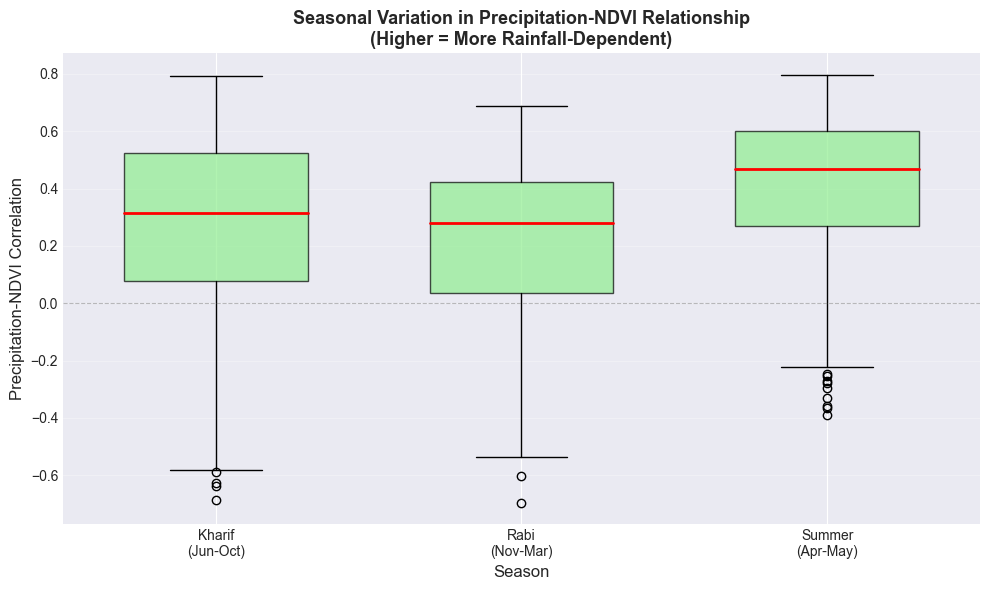

✓ Saved: 07_seasonal_comparison.png


In [54]:
# Define seasons
climate["season"] = climate["month"].map(
    {
        6: "Kharif",
        7: "Kharif",
        8: "Kharif",
        9: "Kharif",
        10: "Kharif",
        11: "Rabi",
        12: "Rabi",
        1: "Rabi",
        2: "Rabi",
        3: "Rabi",
        4: "Summer",
        5: "Summer",
    }
)

# Calculate seasonal correlations
seasonal_corr = (
    climate.groupby(["state", "district", "season"])
    .apply(
        lambda g: (
            g[["precipitation_mm", "raw_ndvi_mean"]].corr().iloc[0, 1]
            if len(g) > 10
            else np.nan
        )
    )
    .reset_index(name="precip_ndvi_corr")
)

seasonal_pivot = seasonal_corr.pivot(
    index=["state", "district"], columns="season", values="precip_ndvi_corr"
)

print("Average correlation by season:")
print(seasonal_pivot.mean())

# Visualization
fig, ax = plt.subplots(figsize=(10, 6))

seasonal_data = [
    seasonal_pivot["Kharif"].dropna(),
    seasonal_pivot["Rabi"].dropna(),
    seasonal_pivot["Summer"].dropna(),
]

bp = ax.boxplot(
    seasonal_data,
    labels=["Kharif\n(Jun-Oct)", "Rabi\n(Nov-Mar)", "Summer\n(Apr-May)"],
    widths=0.6,
    patch_artist=True,
    boxprops=dict(facecolor="lightgreen", alpha=0.7),
    medianprops=dict(color="red", linewidth=2),
)

ax.set_ylabel("Precipitation-NDVI Correlation", fontsize=12)
ax.set_xlabel("Season", fontsize=12)
ax.set_title(
    "Seasonal Variation in Precipitation-NDVI Relationship\n(Higher = More Rainfall-Dependent)",
    fontsize=13,
    fontweight="bold",
)
ax.grid(True, alpha=0.3, axis="y")
ax.axhline(y=0, color="gray", linestyle="--", linewidth=0.8, alpha=0.5)

plt.tight_layout()
plt.savefig(figures_path / "07_seasonal_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

print("✓ Saved: 07_seasonal_comparison.png")

## Analysis 7: Temporal Trends (2016-2026)

In [55]:
# Annual averages
annual_summary = (
    climate.groupby("year")
    .agg({"precipitation_mm": "mean", "raw_ndvi_mean": "mean"})
    .reset_index()
)

# Precipitation trend
slope_precip, intercept, r_value, p_value, std_err = stats.linregress(
    annual_summary["year"], annual_summary["precipitation_mm"]
)
print(
    f"Precipitation trend: {slope_precip:.2f} mm/month per year (R²={r_value**2:.3f}, p={p_value:.3f})"
)

# NDVI trend
slope_ndvi, intercept, r_value, p_value, std_err = stats.linregress(
    annual_summary["year"], annual_summary["raw_ndvi_mean"]
)
print(f"NDVI trend: {slope_ndvi:.4f} per year (R²={r_value**2:.3f}, p={p_value:.3f})")

Precipitation trend: -4.78 mm/month per year (R²=0.283, p=0.092)
NDVI trend: -0.0002 per year (R²=0.002, p=0.902)


## Summary & Key Findings

All 7 analyses completed successfully!

In [56]:
print("SUMMARY STATISTICS")
print("=" * 80)

print(f"\n1. Precipitation-NDVI Correlation:")
print(
    f"   Range: {correlations['precip_ndvi_corr'].min():.3f} to {correlations['precip_ndvi_corr'].max():.3f}"
)
print(f"   Median: {correlations['precip_ndvi_corr'].median():.3f}")

print(f"\n2. Optimal Lag:")
print(f"   Mode: {lag_results['optimal_lag'].mode()[0]} months")
print(
    f"   Distribution: {dict(lag_results['optimal_lag'].value_counts().sort_index())}"
)

print(f"\n3. Agro-Ecological Zones:")
print(f"   Number of clusters: {k_optimal}")
print(
    f"   Average cluster size: {district_summary['cluster'].value_counts().mean():.1f} districts"
)

print(f"\n4. Seasonal Variation:")
print(f"   Kharif correlation:  {seasonal_pivot['Kharif'].median():.3f}")
print(f"   Rabi correlation:    {seasonal_pivot['Rabi'].median():.3f}")
print(f"   Summer correlation:  {seasonal_pivot['Summer'].median():.3f}")

print(f"\n✓ All visualizations saved to: {figures_path}")

SUMMARY STATISTICS

1. Precipitation-NDVI Correlation:
   Range: -0.352 to 0.833
   Median: 0.470

2. Optimal Lag:
   Mode: 1 months
   Distribution: {0: 46, 1: 183, 2: 136, 3: 49}

3. Agro-Ecological Zones:
   Number of clusters: 6
   Average cluster size: 69.0 districts

4. Seasonal Variation:
   Kharif correlation:  0.315
   Rabi correlation:    0.281
   Summer correlation:  0.470

✓ All visualizations saved to: /Users/a0488240/Documents/Learning/MTech/project/dsba2026/figures
